# Teste statistice – Curs 2, temă

Gaita Marian Gabriel

Verificarea rezolvărilor de mână (Problemele 1–5) cu `scipy.stats`. La fiecare punct am refăcut calculul de pe foaie și l-am comparat cu funcția din `scipy.stats`; ✓ înseamnă că valorile coincid. Valorile p sunt bilaterale, α = 0.05.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

try:
    import curs2_stats
except ImportError:  # notebook rulat fără `pip install -e .`
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import curs2_stats

from curs2_stats import data
from curs2_stats import (describe, lilliefors_table, shapiro_wilk_w, one_sample_t, sign_test,
                         wilcoxon_signed_rank, paired_t, independent_t, mann_whitney, mcnemar_exact)

pd.set_option("display.precision", 4)


def check(name, manual, reference, tol=1e-6):
    # Compară valoarea calculată de mână cu cea din scipy.stats; oprește notebook-ul dacă diferă.
    ok = abs(float(manual) - float(reference)) <= tol
    print(f"{'✓' if ok else '✗'} {name}: de mână = {float(manual):.4f} | scipy.stats = {float(reference):.4f}")
    assert ok, f"{name}: valorile diferă"


def decision(reject):
    return "respingem H₀" if reject else "nu respingem H₀"


def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def histogram_with_bell(ax, x, bins, title, unit):
    # Histograma plus clopotul normal cu aceeași medie și abatere standard ("clopotul așteptat").
    d = describe(x)
    ax.hist(x, bins=bins, edgecolor="black", alpha=0.8)
    grid = np.linspace(bins[0], bins[-1], 200)
    width = bins[1] - bins[0]
    ax.plot(grid, stats.norm.pdf(grid, d.mean, d.std) * d.n * width, color="tab:orange", label="clopotul normal")
    ax.axvline(d.mean, linestyle="--", color="black", label=f"media = {d.mean:.2f}")
    ax.set(title=title, xlabel=unit, ylabel="Frecvență")
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.legend(fontsize=8)

---
# Problema 1 · Normalitate: timpul de răspuns al unui model

Timpul de răspuns (ms) al unui model de clasificare, măsurat pe 12 cereri.

- **H₀:** timpii de răspuns provin dintr-o repartiție normală.
- **H₁:** timpii de răspuns nu provin dintr-o repartiție normală.

La testele de normalitate, un p mic este vestea „proastă”: înseamnă că datele **nu** sunt normale.

## Problema 1 · Punctul 1: media, abaterea standard și histograma

$$\bar{x} = \frac{\sum x_i}{n} \qquad s = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n-1}}$$

In [2]:
x1 = np.asarray(data.RESPONSE_TIME_MS, dtype=float)
d1 = describe(x1)
print(f"n = {d1.n},  x̄ = {d1.mean:.2f} ms,  Σ(xᵢ − x̄)² = {d1.sum_of_squares:.2f},  s = {d1.std:.2f} ms,  mediana = {d1.median:g} ms")

check("media", d1.mean, np.mean(x1))
check("abaterea standard", d1.std, np.std(x1, ddof=1))

n = 12,  x̄ = 111.25 ms,  Σ(xᵢ − x̄)² = 6094.25,  s = 23.54 ms,  mediana = 102.5 ms
✓ media: de mână = 111.2500 | scipy.stats = 111.2500
✓ abaterea standard: de mână = 23.5377 | scipy.stats = 23.5377


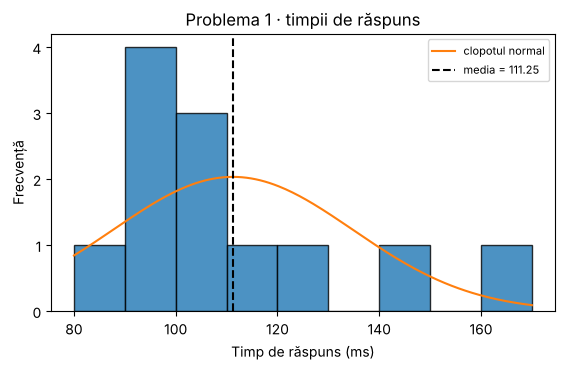

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
histogram_with_bell(ax, x1, np.arange(80, 180, 10), "Problema 1 · timpii de răspuns", "Timp de răspuns (ms)")
plt.show()

Histograma este **asimetrică la dreapta**: 9 din 12 cereri au cel mult 115 ms, iar 142 și 168 ms formează o coadă lungă pe care clopotul normal nu o urmărește. Media (111.25 ms) este trasă spre dreapta față de mediană (102.5 ms).

## Problema 1 · Punctul 2: tabelul Lilliefors

Media și abaterea standard sunt estimate din același eșantion, deci folosim **Lilliefors**, nu K–S clasic (aceeași statistică D, dar cu valori critice corectate).

$$z_i = \frac{x_{(i)} - \bar{x}}{s} \qquad D^+ = \max\left[\frac{i}{n} - \Phi(z_i)\right] \qquad D^- = \max\left[\Phi(z_i) - \frac{i-1}{n}\right] \qquad D = \max(D^+, D^-)$$

In [4]:
lill = lilliefors_table(x1)
table = pd.DataFrame({"x": lill.x, "z": lill.z, "Φ(z)": lill.phi, "i/n": lill.ecdf,
                      "D⁺ᵢ": lill.d_plus, "D⁻ᵢ": lill.d_minus}, index=pd.RangeIndex(1, d1.n + 1, name="i"))
display(table)

i_plus, i_minus = int(np.argmax(lill.d_plus)) + 1, int(np.argmax(lill.d_minus)) + 1
print(f"D⁺ = {lill.d_plus_max:.4f}, atins la i = {i_plus} (x = {lill.x[i_plus - 1]:g})")
print(f"D⁻ = {lill.d_minus_max:.4f}, atins la i = {i_minus} (x = {lill.x[i_minus - 1]:g})")
print(f"D = max(D⁺, D⁻) = {lill.statistic:.4f}   (verificare: 0 ≤ D ≤ 1)")

# Același D ca la Kolmogorov–Smirnov, aplicat pe datele standardizate cu x̄ și s.
check("D", lill.statistic, stats.kstest(lill.z, "norm").statistic)

,x,z,Φ(z),i/n,D⁺ᵢ,D⁻ᵢ
i,,,,,,
1,88.0,-0.9878,0.1616,0.0833,-0.0783,0.1616
2,92.0,-0.8178,0.2067,0.1667,-0.0401,0.1234
3,95.0,-0.6904,0.2450,0.2500,0.0050,0.0783
4,97.0,-0.6054,0.2725,0.3333,0.0609,0.0225
5,99.0,-0.5204,0.3014,0.4167,0.1153,-0.0320
6,101.0,-0.4355,0.3316,0.5000,0.1684,-0.0851
7,104.0,-0.3080,0.3790,0.5833,0.2043,-0.1210
8,108.0,-0.1381,0.4451,0.6667,0.2216,-0.1382
9,115.0,0.1593,0.5633,0.7500,0.1867,-0.1034


D⁺ = 0.2216, atins la i = 8 (x = 108)
D⁻ = 0.1616, atins la i = 1 (x = 88)
D = max(D⁺, D⁻) = 0.2216   (verificare: 0 ≤ D ≤ 1)
✓ D: de mână = 0.2216 | scipy.stats = 0.2216


## Problema 1 · Punctul 3: statistica Shapiro–Wilk W

Perechile se formează dinspre capete spre mijloc, iar coeficienții aᵢ sunt cei de pe linia n = 12 a tabelului.

$$Z^2 = \sum (x_i - \bar{x})^2 \qquad d_i = x_{(n-i+1)} - x_{(i)} \qquad b = \sum a_i \, d_i \qquad W = \frac{b^2}{Z^2}$$

In [5]:
sw = shapiro_wilk_w(x1, data.SHAPIRO_WILK_COEFFICIENTS_N12)
pairs = [f"{hi:g} − {lo:g}" for hi, lo in zip(sw.upper, sw.lower)]
display(pd.DataFrame({"perechea": pairs, "dᵢ": sw.differences, "aᵢ": sw.coefficients, "aᵢ · dᵢ": sw.weighted},
                     index=pd.RangeIndex(1, 7, name="i")))
print(f"b = {sw.b:.4f},  Z² = {sw.sum_of_squares:.2f},  W = b² / Z² = {sw.b ** 2:.2f} / {sw.sum_of_squares:.2f} = {sw.statistic:.4f}")

# scipy aproximează coeficienții aᵢ printr-o formulă, deci W poate diferi foarte puțin de calculul cu tabelul.
check("W", sw.statistic, stats.shapiro(x1).statistic, tol=1e-3)

,perechea,dᵢ,aᵢ,aᵢ · dᵢ
i,,,,
1,168 − 88,80.0,0.5475,43.8000
2,142 − 92,50.0,0.3325,16.6250
3,126 − 95,31.0,0.2347,7.2757
4,115 − 97,18.0,0.1586,2.8548
5,108 − 99,9.0,0.0922,0.8298
6,104 − 101,3.0,0.0303,0.0909


b = 71.4762,  Z² = 6094.25,  W = b² / Z² = 5108.85 / 6094.25 = 0.8383
✓ W: de mână = 0.8383 | scipy.stats = 0.8383


## Problema 1 · Punctul 4: decizia la α = 0.05 și comparația testelor

In [6]:
w_crit = data.SHAPIRO_WILK_W_CRITICAL_N12
p_lill = stats.goodness_of_fit(stats.norm, x1, statistic="ks", rng=0).pvalue   # Lilliefors (Monte Carlo)
p_sw = stats.shapiro(x1).pvalue

display(pd.DataFrame({
    "statistica": [f"D = {lill.statistic:.3f}", f"W = {sw.statistic:.3f}"],
    "valoarea critică": [f"{data.LILLIEFORS_D_CRITICAL_N12}", f"{w_crit[0.05]} (la 1%: {w_crit[0.01]})"],
    "respingem H₀ când": ["D > D critic", "W < W critic"],
    "p (scipy.stats)": [fmt_p(p_lill), fmt_p(p_sw)],
    "decizie la α = 0.05": [decision(lill.reject(data.LILLIEFORS_D_CRITICAL_N12)), decision(sw.reject(w_crit[0.05]))],
}, index=["Lilliefors", "Shapiro–Wilk"]))
print(f"La α = 0.01, Shapiro–Wilk: W = {sw.statistic:.3f} > {w_crit[0.01]}  ->  {decision(sw.reject(w_crit[0.01]))}")

,statistica,valoarea critică,respingem H₀ când,p (scipy.stats),decizie la α = 0.05
Lilliefors,D = 0.222,0.242,D > D critic,p = 0.105,nu respingem H₀
Shapiro–Wilk,W = 0.838,0.859 (la 1%: 0.805),W < W critic,p = 0.026,respingem H₀


La α = 0.01, Shapiro–Wilk: W = 0.838 > 0.805  ->  nu respingem H₀


**Testele nu sunt de acord.** Lilliefors nu respinge normalitatea (D = 0.222 < 0.242), Shapiro–Wilk o respinge (W = 0.838 < 0.859). Shapiro–Wilk respinge la 5%, dar nu și la 1% (0.805 < 0.838), deci 0.01 < p < 0.05.

- Lilliefors se bazează pe o singură valoare: diferența maximă dintre scara datelor și curba normală. Aceasta apare în zona centrală (x = 108 ms), iar testul este puțin sensibil la abaterile din cozi.
- Shapiro–Wilk folosește toate valorile ordonate, iar ponderea cea mai mare o au perechile de la extremități (a₁ = 0.5475 pentru perechea 168 − 88). De aceea detectează asimetria produsă de valorile mari, 142 și 168 ms.

Pentru eșantioane mici (n = 12), Shapiro–Wilk are o putere statistică mai mare și este prima alegere, așa că ne bazăm pe verdictul lui: timpii de răspuns **nu** au repartiție normală. Histograma de la Punctul 1 confirmă coada din dreapta.

> Cursul folosește pentru Lilliefors funcția `lilliefors(x)` din `statsmodels`. În `scipy.stats`, același test se face cu `goodness_of_fit(norm, x, statistic="ks")`, care estimează media și abaterea standard din date și calculează p prin simulare.

---
# Problema 2 · Un grup față de o valoare de referință: tensiunea arterială

Tensiunea arterială sistolică (mmHg) la 12 pacienți. Valoarea de referință este μ₀ = 120 mmHg.

## Pasul zero: sunt datele normale?

Înainte de t-test verificăm normalitatea, cu Shapiro–Wilk și cu histograma.

Shapiro–Wilk: W = 0.980, p = 0.985  ->  nu respingem normalitatea


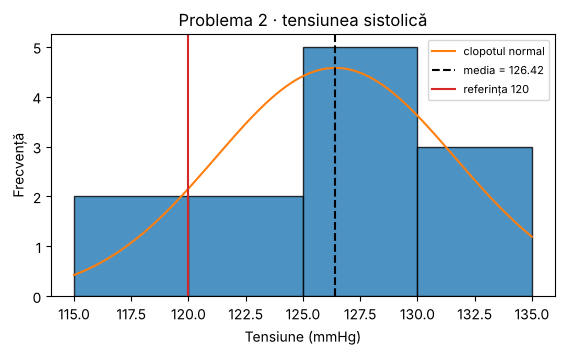

In [7]:
x2 = np.asarray(data.SYSTOLIC_BP_MMHG, dtype=float)
mu0 = data.SYSTOLIC_BP_REFERENCE
print(f"Shapiro–Wilk: W = {stats.shapiro(x2).statistic:.3f}, {fmt_p(stats.shapiro(x2).pvalue)}  ->  nu respingem normalitatea")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
histogram_with_bell(ax, x2, np.arange(115, 140, 5), "Problema 2 · tensiunea sistolică", "Tensiune (mmHg)")
ax.axvline(mu0, color="tab:red", label="referința 120")
ax.legend(fontsize=8)
plt.show()

Datele sunt compatibile cu o repartiție normală, deci t-testul este testul potrivit. Aplicăm apoi și testele neparametrice, cum cere problema.

## Problema 2 · Punctul 1: t-testul pentru un eșantion

1. **Ipoteze:** H₀: μ = 120 mmHg; H₁: μ ≠ 120 mmHg.
2. **Pragul și testul:** α = 0.05, bilateral; t-test pentru un eșantion (date normale).
3. **Statistica:**

$$t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}} \qquad df = n - 1$$

In [8]:
d2 = describe(x2)
t2 = one_sample_t(x2, mu0)
low, high = t2.confidence_interval(data.T_CRITICAL_DF11)

print(f"semnalul:  x̄ − μ₀ = {d2.mean:.2f} − {mu0:g} = {t2.estimate:.2f} mmHg")
print(f"zgomotul:  s / √n = {d2.std:.2f} / √{d2.n} = {t2.standard_error:.3f} mmHg")
print(f"t = {t2.estimate:.2f} / {t2.standard_error:.3f} = {t2.statistic:.2f},  df = {t2.df}")
print(f"|t| = {abs(t2.statistic):.2f} > t critic = {data.T_CRITICAL_DF11}  ->  {decision(t2.reject(data.T_CRITICAL_DF11))}")
print(f"IC 95% pentru medie: {mu0 + low:.2f} – {mu0 + high:.2f} mmHg,  d = {t2.cohen_d:.2f}")

ref = stats.ttest_1samp(x2, mu0)
check("t", t2.statistic, ref.statistic)
print(f"valoarea p (scipy.stats): {fmt_p(ref.pvalue)}")

semnalul:  x̄ − μ₀ = 126.42 − 120 = 6.42 mmHg
zgomotul:  s / √n = 5.23 / √12 = 1.510 mmHg
t = 6.42 / 1.510 = 4.25,  df = 11
|t| = 4.25 > t critic = 2.201  ->  respingem H₀
IC 95% pentru medie: 123.09 – 129.74 mmHg,  d = 1.23
✓ t: de mână = 4.2498 | scipy.stats = 4.2498
valoarea p (scipy.stats): p = 0.001


5. **Concluzie:** tensiunea sistolică medie a pacienților (126.42 mmHg; IC 95%: 123.09 – 129.74) este semnificativ mai mare decât valoarea de referință de 120 mmHg, t(11) = 4.25, p = 0.001. Diferența este de 6.4 mmHg, iar efectul este mare (d = 1.23).

## Problema 2 · Punctul 2: testul semnelor și testul Wilcoxon signed-rank

### Testul semnelor

1. **Ipoteze:** H₀: mediana = 120 mmHg (fiecare pacient are 50% șanse să fie sub sau peste); H₁: mediana ≠ 120 mmHg.
2. **Pragul și testul:** α = 0.05, bilateral. Testul folosește doar semnul diferențelor și nu presupune nimic despre forma repartiției.
3. **Statistica:** numărul de „+”, care sub H₀ urmează repartiția binomială B(n, 0.5). Pentru n mic folosim direct binomiala.

In [9]:
sgn = sign_test(x2, mu0)
print(f"semne: {sgn.n_plus} plusuri, {sgn.n_minus} minusuri, {sgn.n_ties} valori egale cu 120")
print(f"p exact din binomială = {sgn.p_value:.4f}  ->  {decision(sgn.reject(data.ALPHA))}")

check("p testul semnelor", sgn.p_value, stats.binomtest(sgn.n_plus, sgn.n, 0.5).pvalue)

semne: 10 plusuri, 2 minusuri, 0 valori egale cu 120
p exact din binomială = 0.0386  ->  respingem H₀
✓ p testul semnelor: de mână = 0.0386 | scipy.stats = 0.0386


### Testul Wilcoxon signed-rank

1. **Ipoteze:** H₀: diferențele dᵢ = xᵢ − 120 sunt centrate în 0; H₁: nu sunt.
2. **Pragul și testul:** α = 0.05, bilateral. Spre deosebire de testul semnelor, Wilcoxon ține cont și de mărimea diferențelor. Presupune doar o repartiție aproximativ simetrică.
3. **Statistica:** diferențele se ordonează după valoarea absolută și primesc ranguri (valorile egale primesc media rangurilor).

$$W^+ = \sum_{d_i > 0} R_i \qquad W^- = \sum_{d_i < 0} R_i \qquad W^+ + W^- = \frac{n(n+1)}{2} \qquad W = \min(W^+, W^-)$$

In [10]:
wil = wilcoxon_signed_rank(x2, mu0)
ranks_table = pd.DataFrame({"xᵢ": x2.astype(int), "dᵢ": wil.differences, "|dᵢ|": np.abs(wil.differences),
                            "Rᵢ": wil.ranks, "semn": np.where(wil.differences > 0, "+", "−")})
ranks_table = ranks_table.sort_values("|dᵢ|", kind="mergesort").reset_index(drop=True)
ranks_table.index = pd.RangeIndex(1, wil.n + 1, name="i")
display(ranks_table)

print(f"W⁻ = {wil.w_minus:g},  W⁺ = {wil.w_plus:g},  verificare: {wil.w_plus + wil.w_minus:g} = 12 · 13 / 2 = 78")
print(f"W = min(W⁺, W⁻) = {wil.statistic:g} ≤ W critic = {data.WILCOXON_CRITICAL_N12:g}  ->  {decision(wil.reject(data.WILCOXON_CRITICAL_N12))}")

ref = stats.wilcoxon(x2 - mu0)
check("W", wil.statistic, ref.statistic)
print(f"valoarea p (scipy.stats): {fmt_p(ref.pvalue)}")

,xᵢ,dᵢ,|dᵢ|,Rᵢ,semn
i,,,,,
1,119,-1.0,1.0,1.0,−
2,118,-2.0,2.0,2.5,−
3,122,2.0,2.0,2.5,+
4,124,4.0,4.0,4.0,+
5,125,5.0,5.0,5.0,+
6,126,6.0,6.0,6.0,+
7,127,7.0,7.0,7.0,+
8,128,8.0,8.0,8.0,+
9,129,9.0,9.0,9.0,+


W⁻ = 3.5,  W⁺ = 74.5,  verificare: 78 = 12 · 13 / 2 = 78
W = min(W⁺, W⁻) = 3.5 ≤ W critic = 13  ->  respingem H₀
✓ W: de mână = 3.5000 | scipy.stats = 3.5000
valoarea p (scipy.stats): p = 0.003


Pentru n = 12 decizia se ia din tabelul Wilcoxon. Aproximarea normală din curs se folosește pentru n mai mare de aproximativ 20.

## Problema 2 · Punctul 3: comparația celor trei teste

In [11]:
display(pd.DataFrame({
    "tip": ["parametric", "neparametric", "neparametric"],
    "ce folosește din date": ["valorile exacte", "doar semnul (+/−)", "semnul și rangul"],
    "ce presupune": ["normalitate", "nimic despre formă", "simetrie"],
    "statistica": [f"t = {t2.statistic:.2f}", f"{sgn.n_plus}+ / {sgn.n_minus}−", f"W = {wil.statistic:g}"],
    "prag": [f"t critic = {data.T_CRITICAL_DF11}", "α = 0.05", f"W critic = {data.WILCOXON_CRITICAL_N12:g}"],
    "p": [fmt_p(stats.ttest_1samp(x2, mu0).pvalue), fmt_p(sgn.p_value), fmt_p(stats.wilcoxon(x2 - mu0).pvalue)],
    "decizie": [decision(t2.reject(data.T_CRITICAL_DF11)), decision(sgn.reject(data.ALPHA)),
                decision(wil.reject(data.WILCOXON_CRITICAL_N12))],
}, index=["t-test un eșantion", "testul semnelor", "Wilcoxon signed-rank"]))

,tip,ce folosește din date,ce presupune,statistica,prag,p,decizie
t-test un eșantion,parametric,valorile exacte,normalitate,t = 4.25,t critic = 2.201,p = 0.001,respingem H₀
testul semnelor,neparametric,doar semnul (+/−),nimic despre formă,10+ / 2−,α = 0.05,p = 0.039,respingem H₀
Wilcoxon signed-rank,neparametric,semnul și rangul,simetrie,W = 3.5,W critic = 13,p = 0.003,respingem H₀


Toate cele trei teste conduc la aceeași concluzie: tensiunea arterială sistolică medie a pacienților este semnificativ mai mare decât valoarea de referință de 120 mmHg. Faptul că și testele neparametrice, care nu presupun normalitatea datelor, resping H₀ arată că rezultatul este robust.

Valorile p cresc pe măsură ce testul folosește mai puțină informație din date: testul semnelor, care vede doar „+” sau „−”, are p-ul cel mai mare. Testul principal rămâne t-testul, ales după tipul datelor (normale), nu după rezultat.

---
# Problema 3 · Date pereche: acuratețea înainte și după augmentare

## Problema 3 · Punctul 1: de ce datele sunt pereche

Întrebarea de control din curs: *are sens să tragem o linie între o valoare anume din primul grup și una anume din al doilea?* Aici da. Același model este evaluat pe **aceleași 10 seturi de date**, iar valoarea „după” a setului 1 îi corespunde valorii „înainte” a setului 1, și tot așa. Ordinea nu poate fi amestecată fără să pierdem informație.

Fiecare set de date este propriul său martor. Faptul că unele seturi sunt mai grele (~78%) și altele mai ușoare (~85%) nu mai contează: ne uităm doar la cât s-a schimbat acuratețea pe fiecare set.

## Problema 3 · Punctul 2: t-testul pereche

1. **Ipoteze:** H₀: media diferențelor este 0 (augmentarea nu schimbă acuratețea); H₁: media diferențelor este diferită de 0.
2. **Pragul și testul:** α = 0.05, bilateral; t-test pereche, adică t-testul pentru un eșantion aplicat diferențelor, cu referința 0.
3. **Statistica:**

$$d_i = \text{după}_i - \text{înainte}_i \qquad t = \frac{\bar{d} - 0}{s_d / \sqrt{n}} \qquad df = n - 1$$

In [12]:
before = np.asarray(data.ACCURACY_BEFORE, dtype=float)
after = np.asarray(data.ACCURACY_AFTER, dtype=float)
diffs = after - before
display(pd.DataFrame({"înainte": before, "după": after, "dᵢ": diffs}, index=pd.RangeIndex(1, 11, name="setul")))

# Normalitatea se verifică pe coloana diferențelor, nu pe „înainte” și „după” separat.
print(f"Shapiro–Wilk pe diferențe: W = {stats.shapiro(diffs).statistic:.3f}, {fmt_p(stats.shapiro(diffs).pvalue)}  ->  nu respingem normalitatea")

,înainte,după,dᵢ
setul,,,
1,81.2,83.0,1.8
2,78.5,79.1,0.6
3,85.1,86.9,1.8
4,79.9,82.4,2.5
5,83.4,83.1,-0.3
6,77.8,80.2,2.4
7,84.6,86.0,1.4
8,80.3,82.5,2.2
9,82.7,84.9,2.2


Shapiro–Wilk pe diferențe: W = 0.901, p = 0.222  ->  nu respingem normalitatea


In [13]:
dd = describe(diffs)
tp = paired_t(after, before)
low, high = tp.confidence_interval(data.T_CRITICAL_DF9)

print(f"d̄ = {dd.mean:.2f},  s_d = {dd.std:.4f},  SE = s_d / √n = {tp.standard_error:.4f}")
print(f"t = {tp.estimate:.2f} / {tp.standard_error:.4f} = {tp.statistic:.2f},  df = {tp.df}")
print(f"|t| = {abs(tp.statistic):.2f} > t critic = {data.T_CRITICAL_DF9}  ->  {decision(tp.reject(data.T_CRITICAL_DF9))}")
print(f"IC 95% pentru diferența medie: {low:.2f} – {high:.2f} puncte procentuale,  d = {tp.cohen_d:.2f}")

ref = stats.ttest_rel(after, before)
check("t pereche", tp.statistic, ref.statistic)
print(f"valoarea p (scipy.stats): {fmt_p(ref.pvalue)}")

d̄ = 1.55,  s_d = 0.9046,  SE = s_d / √n = 0.2861
t = 1.55 / 0.2861 = 5.42,  df = 9
|t| = 5.42 > t critic = 2.262  ->  respingem H₀
IC 95% pentru diferența medie: 0.90 – 2.20 puncte procentuale,  d = 1.71
✓ t pereche: de mână = 5.4183 | scipy.stats = 5.4183
valoarea p (scipy.stats): p < 0.001


5. **Concluzie:** augmentarea datelor a crescut semnificativ acuratețea modelului, în medie cu 1.55 puncte procentuale (IC 95%: 0.90 – 2.20), t(9) = 5.42, p < 0.001. Creșterea apare pe 9 din cele 10 seturi de date.

## Problema 3 · Punctul 3: același calcul ca pentru grupuri independente

Tratăm, greșit, cele două coloane ca și cum ar proveni din seturi de date diferite: varianță comună și df = 10 + 10 − 2 = 18 (t critic = 2.101).

In [14]:
ti = independent_t(after, before)
check("t independent", ti.statistic, stats.ttest_ind(after, before).statistic)

display(pd.DataFrame({
    "t-test pereche (corect)": [f"{tp.estimate:.2f}", f"{tp.standard_error:.4f}", f"{tp.statistic:.2f}", tp.df,
                                data.T_CRITICAL_DF9, decision(tp.reject(data.T_CRITICAL_DF9))],
    "t-test independent (greșit)": [f"{ti.estimate:.2f}", f"{ti.standard_error:.4f}", f"{ti.statistic:.2f}", ti.df,
                                    data.T_CRITICAL_DF18, decision(ti.reject(data.T_CRITICAL_DF18))],
}, index=["semnalul (diferența mediilor)", "zgomotul (eroarea standard)", "t", "df", "t critic", "decizie"]))
print(f"Zgomotul este de {ti.standard_error / tp.standard_error:.1f} ori mai mare în calculul independent.")

✓ t independent: de mână = 1.3439 | scipy.stats = 1.3439


,t-test pereche (corect),t-test independent (greșit)
semnalul (diferența mediilor),1.55,1.55
zgomotul (eroarea standard),0.2861,1.1533
t,5.42,1.34
df,9,18
t critic,2.262,2.101
decizie,respingem H₀,nu respingem H₀


Zgomotul este de 4.0 ori mai mare în calculul independent.


**Ce se schimbă:** semnalul este același (1.55), dar zgomotul (eroarea standard) este de aproximativ 4 ori mai mare în calculul independent. De aceea t scade de la 5.42 la 1.34, iar rezultatul nu mai este semnificativ.

**De ce:** în calculul independent, împrăștierea include și diferențele dintre seturile de date (s ≈ 2.58): unele seturi au acuratețe în jur de 78%, altele în jur de 85%, indiferent de augmentare. Această variație mare acoperă efectul augmentării. În calculul pereche, fiecare set este comparat cu el însuși, diferențele dintre seturi se elimină și rămâne doar variația creșterilor (s_d ≈ 0.90).

Un test independent pe date pereche crește inutil zgomotul și poate rata un efect real. Aici chiar îl ratează și ar duce la concluzia greșită că augmentarea nu are efect.

---
# Problema 4 · Două grupuri independente: durata spitalizării

Pacienții sunt **diferiți** în cele două grupuri, deci datele sunt independente: nu putem trage o linie între un pacient anume din A și unul anume din B.

## Problema 4 · Punctul 1: verificarea condițiilor și t-testul independent

1. **Ipoteze:** H₀: μ_A = μ_B (cele două tratamente au aceeași durată medie de spitalizare); H₁: μ_A ≠ μ_B.
2. **Pragul și testul:** α = 0.05, bilateral; t-test pentru eșantioane independente, dacă sunt îndeplinite cele trei condiții din curs:
   - **independența:** pacienți diferiți, fiecare apare o singură dată;
   - **normalitatea în fiecare grup**, separat: Shapiro–Wilk și histograma;
   - **varianțe apropiate:** abaterea standard mai mare este sub dublul celei mai mici (și testul Levene).

,n,media,mediana,s²,s,Shapiro–Wilk
tratamentul A,10,7.1000,7.0,2.7667,1.6633,p = 0.646
tratamentul B,12,10.1667,10.0,4.5152,2.1249,p = 0.895


raportul abaterilor standard: 2.12 / 1.66 = 1.28 < 2
raportul varianțelor (verificarea de pe foaie): 4.52 / 2.77 = 1.63 < 2
Levene: p = 0.451  ->  nu respingem egalitatea varianțelor


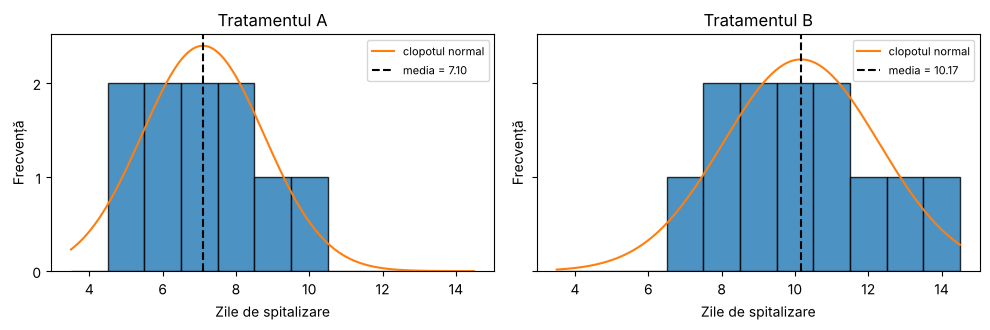

In [15]:
a = np.asarray(data.HOSPITAL_STAY_A, dtype=float)
b = np.asarray(data.HOSPITAL_STAY_B, dtype=float)
dA, dB = describe(a), describe(b)
display(pd.DataFrame({"n": [dA.n, dB.n], "media": [dA.mean, dB.mean], "mediana": [dA.median, dB.median],
                      "s²": [dA.variance, dB.variance], "s": [dA.std, dB.std],
                      "Shapiro–Wilk": [fmt_p(stats.shapiro(a).pvalue), fmt_p(stats.shapiro(b).pvalue)]},
                     index=["tratamentul A", "tratamentul B"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
histogram_with_bell(axes[0], a, np.arange(3.5, 15.5, 1), "Tratamentul A", "Zile de spitalizare")
histogram_with_bell(axes[1], b, np.arange(3.5, 15.5, 1), "Tratamentul B", "Zile de spitalizare")
plt.tight_layout()
plt.show()

t4 = independent_t(a, b)
print(f"raportul abaterilor standard: {dB.std:.2f} / {dA.std:.2f} = {t4.std_ratio:.2f} < 2")
print(f"raportul varianțelor (verificarea de pe foaie): {dB.variance:.2f} / {dA.variance:.2f} = {t4.variance_ratio:.2f} < 2")
print(f"Levene: {fmt_p(stats.levene(a, b).pvalue)}  ->  nu respingem egalitatea varianțelor")

Toate condițiile sunt îndeplinite: grupurile sunt independente, Shapiro–Wilk nu respinge normalitatea în niciun grup, iar varianțele sunt apropiate. Pe foaie am verificat raportul varianțelor (1.63 < 2), o variantă mai strictă a regulii din curs, care se aplică pe abaterile standard (1.28 < 2); ambele duc la aceeași concluzie.

3. **Statistica:**

$$s_p^2 = \frac{(n_A-1)s_A^2 + (n_B-1)s_B^2}{n_A+n_B-2} \qquad SE = s_p\sqrt{\frac{1}{n_A}+\frac{1}{n_B}} \qquad t = \frac{\bar{x}_A - \bar{x}_B}{SE} \qquad df = n_A + n_B - 2$$

In [16]:
print(f"s_p² = (9 · {dA.variance:.3f} + 11 · {dB.variance:.3f}) / 20 = {t4.pooled_std ** 2:.3f}  ->  s_p = {t4.pooled_std:.3f}")
print(f"SE = {t4.pooled_std:.3f} · √(1/10 + 1/12) = {t4.standard_error:.3f}")
print(f"t = ({dA.mean:.2f} − {dB.mean:.2f}) / {t4.standard_error:.3f} = {t4.statistic:.2f},  df = {t4.df}")
print(f"|t| = {abs(t4.statistic):.2f} > t critic = {data.T_CRITICAL_DF20}  ->  {decision(t4.reject(data.T_CRITICAL_DF20))}")

ref = stats.ttest_ind(a, b)
check("t independent", t4.statistic, ref.statistic)
print(f"valoarea p (scipy.stats): {fmt_p(ref.pvalue)}")

s_p² = (9 · 2.767 + 11 · 4.515) / 20 = 3.728  ->  s_p = 1.931
SE = 1.931 · √(1/10 + 1/12) = 0.827
t = (7.10 − 10.17) / 0.827 = -3.71,  df = 20
|t| = 3.71 > t critic = 2.086  ->  respingem H₀
✓ t independent: de mână = -3.7093 | scipy.stats = -3.7093
valoarea p (scipy.stats): p = 0.001


## Problema 4 · Punctul 2: testul Mann–Whitney

1. **Ipoteze:** H₀: cele două tratamente au aceeași repartiție a duratei de spitalizare; H₁: duratele diferă între tratamente.
2. **Pragul și testul:** α = 0.05, bilateral; Mann–Whitney, echivalentul neparametric al t-testului independent. Lucrează cu ranguri, deci nu presupune normalitatea.
3. **Statistica:** punem laolaltă cele 22 de valori, le ordonăm și le dăm ranguri (valorile egale primesc rangul mediu), apoi adunăm rangurile fiecărui grup.

$$R_A + R_B = \frac{N(N+1)}{2} \qquad U_A = R_A - \frac{n_A(n_A+1)}{2} \qquad U_B = R_B - \frac{n_B(n_B+1)}{2} \qquad U = \min(U_A, U_B)$$

In [17]:
mw = mann_whitney(a, b)
values = np.concatenate([a, b])
all_ranks = np.concatenate([mw.ranks_a, mw.ranks_b])
unique = np.unique(values)
display(pd.DataFrame({"din A": [int((a == v).sum()) for v in unique],
                      "din B": [int((b == v).sum()) for v in unique],
                      "rang": [all_ranks[values == v][0] for v in unique]},
                     index=pd.Index(unique.astype(int), name="valoare")))

print(f"R_A = {mw.rank_sum_a:g},  R_B = {mw.rank_sum_b:g},  verificare: {mw.rank_sum_a + mw.rank_sum_b:g} = 22 · 23 / 2 = 253")
print(f"U_A = {mw.rank_sum_a:g} − 55 = {mw.u_a:g},  U_B = {mw.rank_sum_b:g} − 78 = {mw.u_b:g},  verificare: {mw.u_a + mw.u_b:g} = 10 · 12")
print(f"U = {mw.statistic:g} ≤ U critic = {data.MANN_WHITNEY_U_CRITICAL_10_12:g}  ->  {decision(mw.reject(data.MANN_WHITNEY_U_CRITICAL_10_12))}")
print(f"aproximarea normală (curs, T = R_A): z = {mw.z:.2f},  {fmt_p(mw.p_value_normal)}")

ref = stats.mannwhitneyu(a, b)
check("U", mw.statistic, ref.statistic)
print(f"valoarea p (scipy.stats): {fmt_p(ref.pvalue)}")

,din A,din B,rang
valoare,,,
5,2,0,1.5
6,2,0,3.5
7,2,1,6.0
8,2,2,9.5
9,1,2,13.0
10,1,2,16.0
11,0,2,18.5
12,0,1,20.0
13,0,1,21.0


R_A = 70,  R_B = 183,  verificare: 253 = 22 · 23 / 2 = 253
U_A = 70 − 55 = 15,  U_B = 183 − 78 = 105,  verificare: 120 = 10 · 12
U = 15 ≤ U critic = 29  ->  respingem H₀
aproximarea normală (curs, T = R_A): z = -2.97,  p = 0.003
✓ U: de mână = 15.0000 | scipy.stats = 15.0000
valoarea p (scipy.stats): p = 0.003


Rangurile 1–4 aparțin în întregime grupului A, iar rangurile 18–22 grupului B. U = 15 înseamnă că, din cele 10 × 12 = 120 de perechi posibile (un pacient din A, unul din B), doar în aproximativ 15 pacientul din A a stat mai mult în spital. Valoarea p din `scipy.stats` diferă foarte puțin de cea din aproximarea normală, pentru că programul micșorează σ din cauza valorilor egale, cum se precizează și în curs.

Cele două teste sunt de acord, deci concluzia este solidă și nu depinde de presupunerea de normalitate.

## Problema 4 · Punctul 3: fraza de rezultat, cu interval de încredere

$$IC_{95\%} = (\bar{x}_B - \bar{x}_A) \pm t_{critic} \cdot SE$$

In [18]:
diff_ba = independent_t(b, a)
low, high = diff_ba.confidence_interval(data.T_CRITICAL_DF20)
print(f"diferența B − A = {diff_ba.estimate:.2f} zile")
print(f"IC 95% = {diff_ba.estimate:.2f} ± {data.T_CRITICAL_DF20} · {diff_ba.standard_error:.3f} = [{low:.2f}; {high:.2f}] zile")
print(f"mărimea efectului: d = {diff_ba.estimate:.2f} / {diff_ba.pooled_std:.3f} = {diff_ba.cohen_d:.2f}")

ci = stats.ttest_ind(b, a).confidence_interval()
check("limita inferioară a IC", low, ci.low, tol=1e-3)
check("limita superioară a IC", high, ci.high, tol=1e-3)

diferența B − A = 3.07 zile
IC 95% = 3.07 ± 2.086 · 0.827 = [1.34; 4.79] zile
mărimea efectului: d = 3.07 / 1.931 = 1.59
✓ limita inferioară a IC: de mână = 1.3421 | scipy.stats = 1.3421
✓ limita superioară a IC: de mână = 4.7913 | scipy.stats = 4.7913


> Pacienții tratați cu A au avut o durată de spitalizare semnificativ mai scurtă (M = 7.1 zile, s = 1.66) decât cei tratați cu B (M = 10.17 zile, s = 2.12), t-test independent bilateral, t(20) = −3.71, p = 0.001. Diferența medie a fost de 3.07 zile (IC 95%: 1.34 – 4.79 zile), un efect mare (d = 1.59). Testul Mann–Whitney confirmă rezultatul (U = 15, p = 0.003).

---
# Problema 5 · Răspunsuri scurte

## Problema 5 · Punctul 1: Lilliefors D = 1.28

**Răspuns:** testul Lilliefors compară distribuția datelor cu o distribuție normală. Statistica D este cea mai mare diferență dintre două proporții cumulative: proporția observată în date și cea așteptată dacă datele ar fi normale. Ambele proporții sunt între 0 și 1, deci și diferența lor este între 0 și 1. Colegul a folosit scorurile z în loc de probabilitățile Φ(z).

**Ilustrare** pe datele din Problema 1:

In [19]:
correct = lill.statistic
wrong = max(np.max(lill.ecdf - lill.z), np.max(lill.z - (lill.ecdf - 1 / d1.n)))
print(f"D corect, cu Φ(zᵢ):          {correct:.3f}")
print(f"D greșit, cu zᵢ în loc de Φ(zᵢ): {wrong:.3f}  (> 1, imposibil pentru o diferență de proporții)")

D corect, cu Φ(zᵢ):          0.222
D greșit, cu zᵢ în loc de Φ(zᵢ): 1.494  (> 1, imposibil pentru o diferență de proporții)


## Problema 5 · Punctul 2: abaterea standard și eroarea standard

**Răspuns:** abaterea standard arată cât de diferite sunt valorile între ele. Eroarea standard arată cât de bine am estimat media.

*Exemplu:* o pagină web se încarcă, la 25 de accesări, în medie în 2 secunde, cu abaterea standard 0.5 s. Eroarea standard este 0.5 / √25 = 0.1 s. La mai multe accesări, abaterea standard rămâne aceeași, dar eroarea standard scade.

**Ilustrare:** simulăm timpi de încărcare cu media 2 s și abaterea standard 0.5 s.

In [20]:
print(f"exemplul de pe foaie: SE = 0.5 / √25 = {0.5 / np.sqrt(25):.1f} s")

rng = np.random.default_rng(28)
rows = []
for n in (25, 100, 1000):
    sample = describe(rng.normal(2.0, 0.5, n))
    rows.append({"accesări (n)": n, "media (s)": sample.mean, "abaterea standard s (s)": sample.std,
                 "eroarea standard s/√n (s)": sample.standard_error})
display(pd.DataFrame(rows).set_index("accesări (n)"))

exemplul de pe foaie: SE = 0.5 / √25 = 0.1 s


,media (s),abaterea standard s (s),eroarea standard s/√n (s)
accesări (n),,,
25,2.0116,0.4943,0.0989
100,2.0135,0.5073,0.0507
1000,2.0022,0.4991,0.0158


Abaterea standard rămâne în jur de 0.5 s, pentru că accesările nu devin mai asemănătoare între ele. Eroarea standard scade, pentru că media este estimată tot mai precis.

## Problema 5 · Punctul 3: p = 0.30 și „tratamentele sunt identice”

**Răspuns:** un p = 0.30 arată doar că studiul nu a găsit o diferență semnificativă, nu că tratamentele sunt identice. Diferența poate exista, dar studiul, de exemplu cu prea puțini pacienți, nu a detectat-o.

**Ilustrare:** două tratamente care **diferă real** cu 1 zi de spitalizare (s = 2 zile). Numărăm în câte studii simulate diferența nu este detectată.

In [21]:
rng = np.random.default_rng(7)
for n in (8, 20, 60):
    missed = np.mean([stats.ttest_ind(rng.normal(8, 2, n), rng.normal(9, 2, n)).pvalue >= 0.05 for _ in range(2000)])
    print(f"{n:>2} pacienți pe grup: diferența reală nu este detectată în {missed:.0%} din studii")

 8 pacienți pe grup: diferența reală nu este detectată în 84% din studii
20 pacienți pe grup: diferența reală nu este detectată în 65% din studii
60 pacienți pe grup: diferența reală nu este detectată în 22% din studii


Cu puțini pacienți, majoritatea studiilor nu găsesc diferența, deși ea există. Cum spune cursul, „nesemnificativ” nu înseamnă „identic”: lipsa dovezilor nu este dovada lipsei. Intervalul de încredere al diferenței ar fi arătat cât de mari sunt diferențele care nu pot fi excluse.

## Problema 5 · Punctul 4: compararea a două rețele

**Răspuns:** pe aceleași 20 de imagini, rezultatele sunt pereche, așa că folosesc testul McNemar, care compară doar imaginile pe care greșește una dintre rețele iar cealaltă nu. Pe imagini diferite, rezultatele sunt independente, așa că folosesc t-testul independent.

**Ilustrare:** două rețele evaluate pe aceleași 20 de imagini (corect/greșit pe fiecare imagine).

In [22]:
rng = np.random.default_rng(4)
difficulty = rng.uniform(0, 1, 20)     # unele imagini sunt grele pentru ambele rețele
net1 = difficulty < 0.65               # rețeaua 1: corectă doar pe imaginile mai ușoare
net2 = difficulty < 0.95               # rețeaua 2: corectă și pe imagini mai grele

both = int((net1 & net2).sum()); neither = int((~net1 & ~net2).sum())
mc = mcnemar_exact(net2, net1)
print(f"ambele corecte: {both}, ambele greșite: {neither}  (nu spun nimic despre care rețea e mai bună)")
print(f"doar rețeaua 2 corectă: {mc.only_first_correct},  doar rețeaua 1 corectă: {mc.only_second_correct}")
print(f"McNemar exact: {fmt_p(mc.p_value)}  ->  {decision(mc.reject(data.ALPHA))}")

check("p McNemar", mc.p_value,
      stats.binomtest(mc.only_first_correct, mc.only_first_correct + mc.only_second_correct, 0.5).pvalue)

ambele corecte: 11, ambele greșite: 3  (nu spun nimic despre care rețea e mai bună)
doar rețeaua 2 corectă: 6,  doar rețeaua 1 corectă: 0
McNemar exact: p = 0.031  ->  respingem H₀
✓ p McNemar: de mână = 0.0312 | scipy.stats = 0.0312


Imaginile pe care ambele rețele răspund la fel sunt ignorate. Testul compară doar cele 6 imagini pe care rețelele nu sunt de acord: este testul semnelor aplicat dezacordurilor.

Cursul dă chiar acest exemplu de date pereche („aceeași imagine, clasificată de două rețele”). Dacă pentru fiecare imagine avem un scor continuu în loc de corect/greșit, varianta din curs este t-testul pereche (sau Wilcoxon pe diferențe, dacă diferențele nu sunt normale).